In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq
from scipy.signal import butter, filtfilt, dlti, dlsim, detrend, ss2tf, tf2ss, bode
from pysid import armax, oe, bj
from IPython.display import display, Math
from scipy.signal import TransferFunction, lsim
from scipy.optimize import minimize
from sklearn.metrics import mean_squared_error


### **1.** Exploración de los datos

In [4]:
# Cargar datos
data= pd.read_csv("Dataset5.csv")
data.head()


,t,u1,y1,uv,yv,u2,y2
0,0.00,-15.544802,2.500000,14.579503,30.200000,-17.279690,10.800000
1,0.01,-13.422689,4.018034,16.111617,32.018034,-15.227577,12.318034
2,0.02,-16.430372,4.202113,13.253933,32.502113,-18.075261,12.502113
3,0.03,-16.400372,2.818034,13.483933,31.318034,-17.825261,11.218034
4,0.04,-13.132689,0.924429,16.441617,29.624429,-14.467577,9.424429


In [5]:
# Sujeto 1
u1 = np.array(data.u1)
y1 = np.array(data.y1)

# Sujeto 2
u2 = np.array(data.u2)
y2 = np.array(data.y2)

# Data de validación
uv = np.array(data.uv)
yv = np.array(data.yv)

# Tiempo
t = np.array(data.t)

print(len(u1))
print(len(u2))
print(len(uv))
print(len(t))

3001
3001
3001
3001


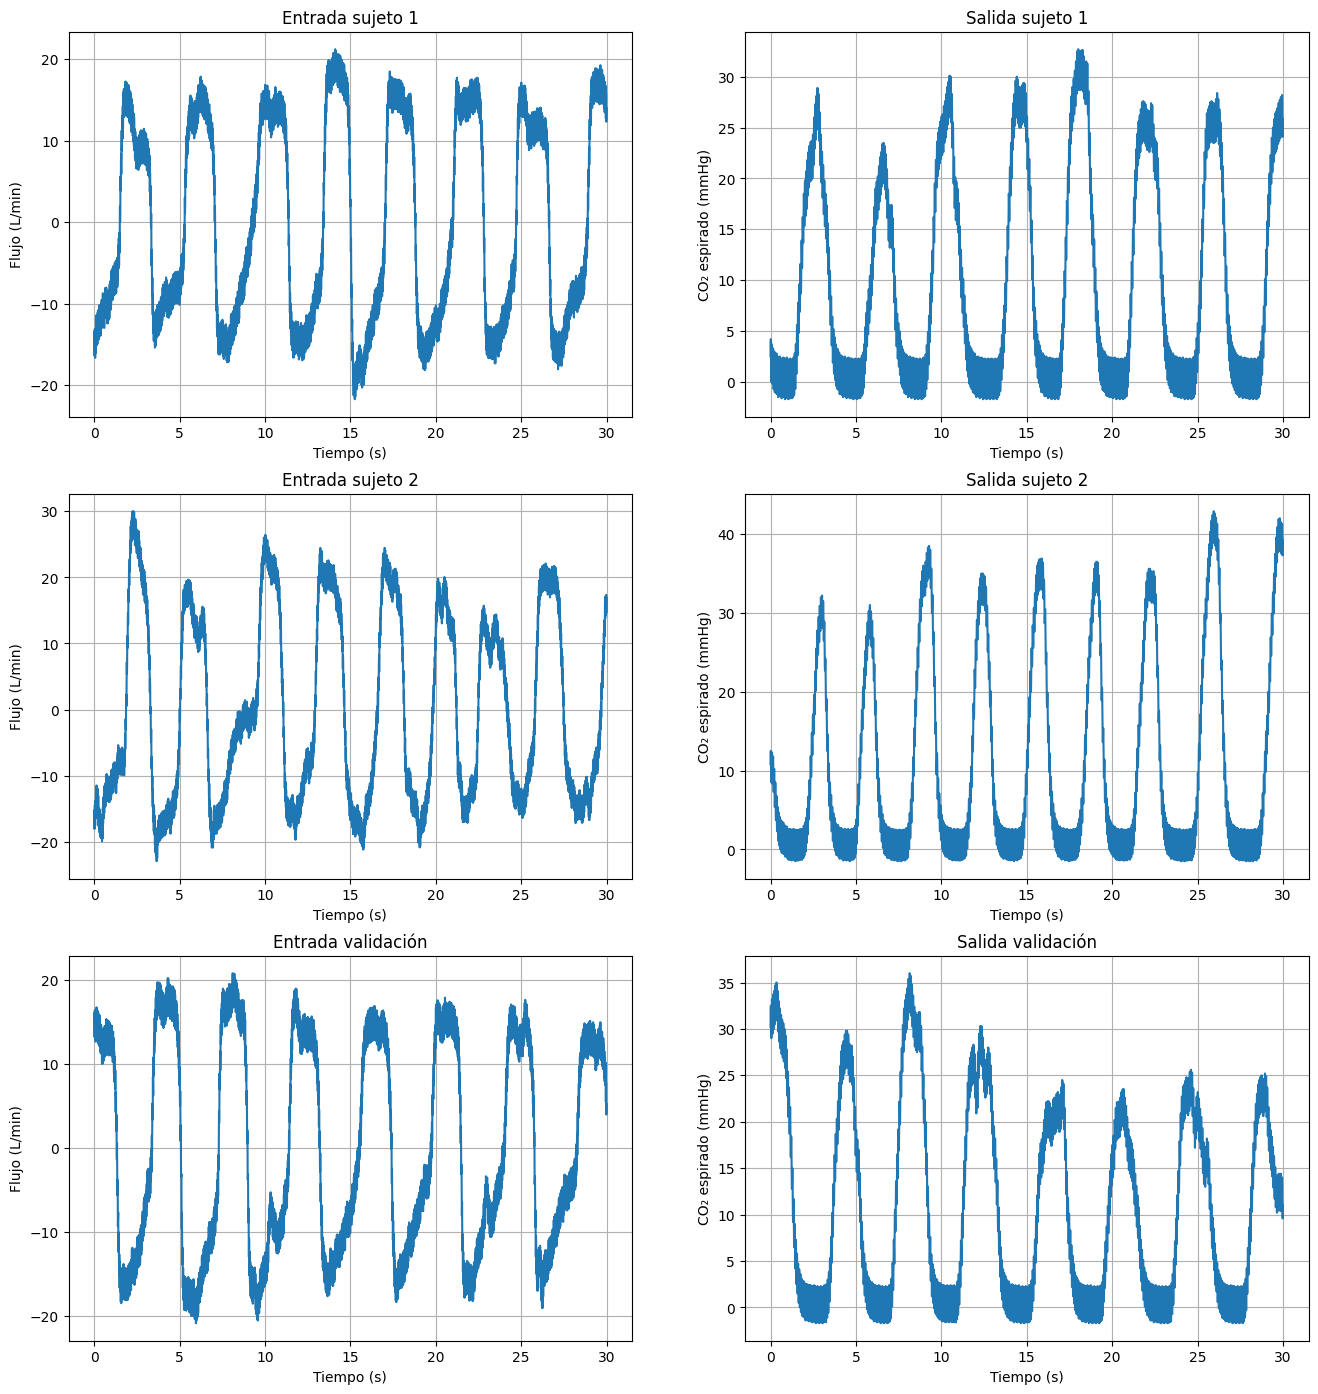

In [6]:
plt.figure(figsize=(16,17))

# Entrada y salida del sujeto 1
plt.subplot(321)
plt.plot(t, u1)
plt.title("Entrada sujeto 1")
plt.xlabel("Tiempo (s)")
plt.ylabel("Flujo (L/min)")
plt.grid()

plt.subplot(322)
plt.plot(t, y1)
plt.title("Salida sujeto 1")
plt.xlabel("Tiempo (s)")
plt.ylabel("CO₂ espirado (mmHg)")
plt.grid()

# Entrada y salida sujeto 2
plt.subplot(323)
plt.plot(t, u2)
plt.title("Entrada sujeto 2")
plt.xlabel("Tiempo (s)")
plt.ylabel("Flujo (L/min)")
plt.grid()

plt.subplot(324)
plt.plot(t, y2)
plt.title("Salida sujeto 2")
plt.xlabel("Tiempo (s)")
plt.ylabel("CO₂ espirado (mmHg)")
plt.grid()

# Entrada y salida data de validación
plt.subplot(325)
plt.plot(t, uv)
plt.title("Entrada validación")
plt.xlabel("Tiempo (s)")
plt.ylabel("Flujo (L/min)")
plt.grid()

plt.subplot(326)
plt.plot(t, yv)
plt.title("Salida validación")
plt.xlabel("Tiempo (s)")
plt.ylabel("CO₂ espirado (mmHg)")
plt.grid()

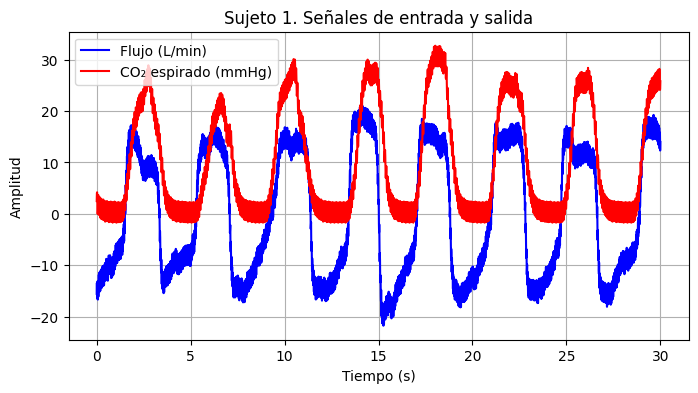

In [7]:
plt.figure(figsize=(8,4))
plt.plot(t, u1, 'b', label='Flujo (L/min)')
plt.plot(t, y1, 'r', label='CO₂ espirado (mmHg)')
plt.title("Sujeto 1. Señales de entrada y salida")
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()

### **2.** Frecuencias del flujo y CO₂ espirado
#### **2.1.** Sujeto 1:

(0.0, 40.0)

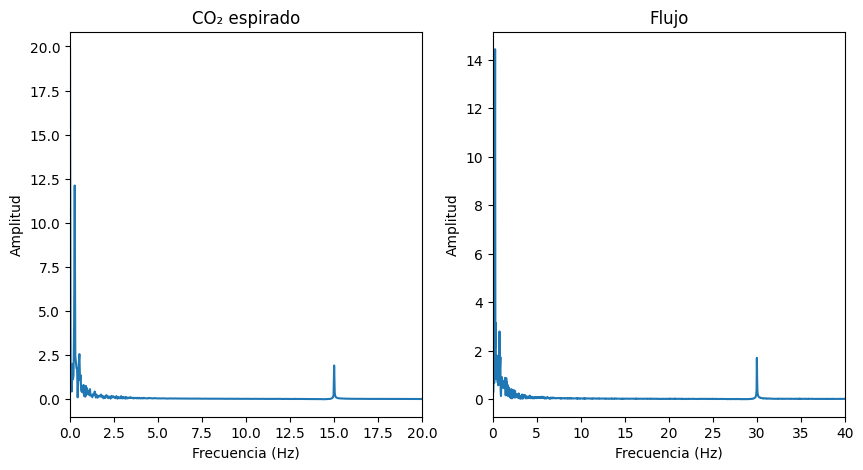

In [8]:
ts= np.mean(np.diff(t))

# Flujo
N_u1 = len(u1)
yu = fft(u1)
xu = fftfreq(N_u1, ts)[:N_u1//2]

# CO₂ espirado
N_y1 = len(y1)
yf = fft(y1)
xf = fftfreq(N_y1, ts)[:N_y1//2]

# Graficos
plt.figure(figsize=(10,5))
plt.subplot(121)
plt.plot(xf, 2.0/ N_y1*np.abs(yf[0:N_y1//2]))
plt.title("CO₂ espirado")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0,20)

plt.subplot(122)
plt.plot(xu, 2.0/ N_u1*np.abs(yu[0:N_u1//2]))
plt.title("Flujo")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0,40)


#### **2.2.** Sujeto 2:

(0.0, 40.0)

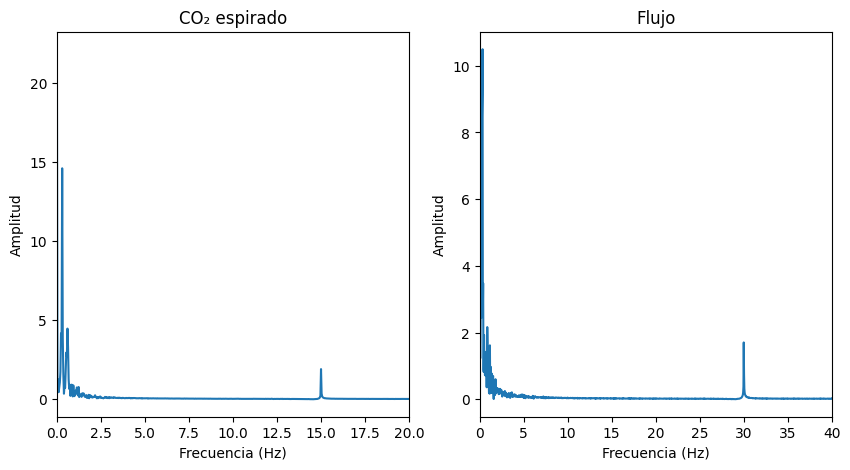

In [9]:
# Flujo
N_u2 = len(u2)
yu2 = fft(u2)
xu2 = fftfreq(N_u2, ts)[:N_u2//2]

# CO₂ espirado
N_y2 = len(y2)
yf2 = fft(y2)
xf2 = fftfreq(N_y2, ts)[:N_y2//2]

# Graficos
plt.figure(figsize=(10,5))
plt.subplot(121)
plt.plot(xf2, 2.0/ N_y2*np.abs(yf2[0:N_y2//2]))
plt.title("CO₂ espirado")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0,20)

plt.subplot(122)
plt.plot(xu2, 2.0/ N_u2*np.abs(yu2[0:N_u2//2]))
plt.title("Flujo")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0,40)

#### **2.3.** Datos validación:

(0.0, 40.0)

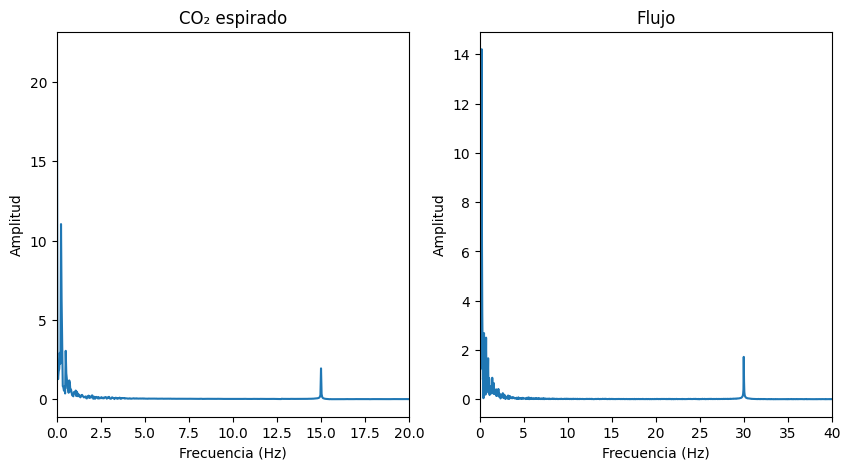

In [10]:
# Flujo
N_uv = len(uv)
yuv = fft(uv)
xuv = fftfreq(N_uv, ts)[:N_uv//2]

# CO₂ espirado
N_yv = len(yv)
yfv = fft(yv)
xfv = fftfreq(N_yv, ts)[:N_yv//2]

# Graficos
plt.figure(figsize=(10,5))
plt.subplot(121)
plt.plot(xfv, 2.0/ N_yv*np.abs(yfv[0:N_yv//2]))
plt.title("CO₂ espirado")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0,20)

plt.subplot(122)
plt.plot(xuv, 2.0/ N_uv*np.abs(yuv[0:N_uv//2]))
plt.title("Flujo")
plt.xlabel("Frecuencia (Hz)")
plt.ylabel("Amplitud")
plt.xlim(0,40)

### **3.** Filtro y Detrend
#### **3.1.** Se realiza filtro para las entradas (Flujo)

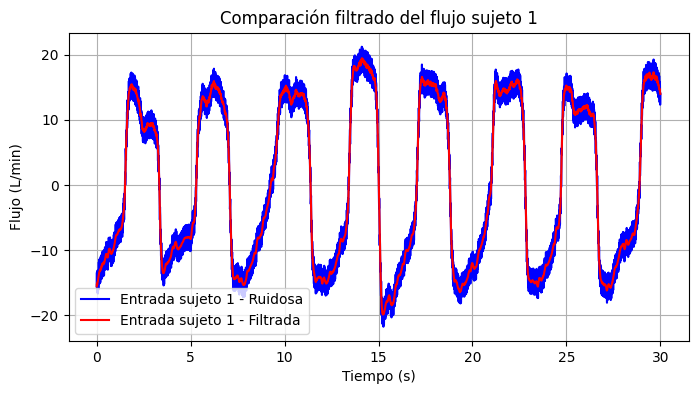

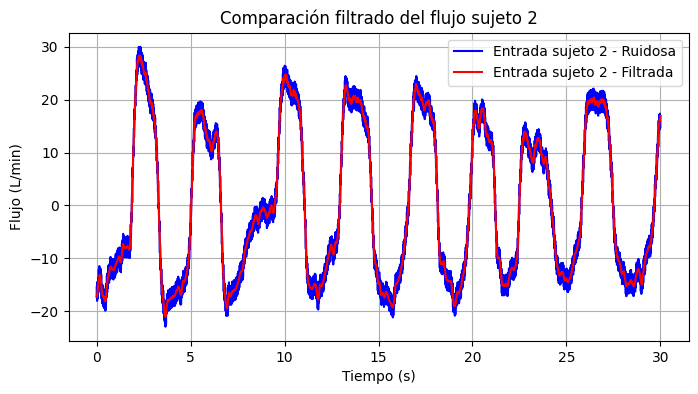

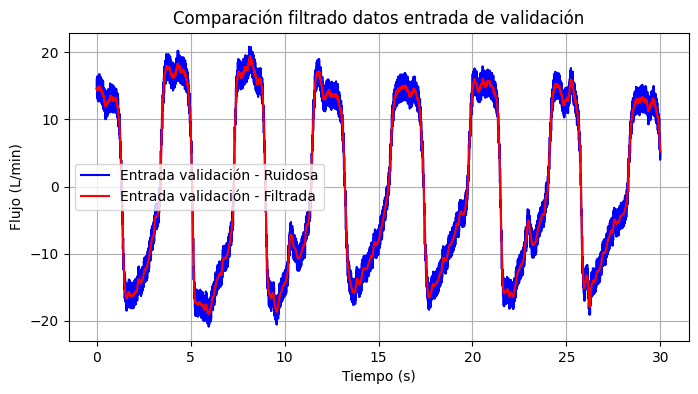

In [11]:
# Filtro para el flujo
fs = 1/ts

b,a = butter(3,[29,31], btype='stop', fs=fs)
c,d = butter(3,[29,31], btype='stop', fs=fs)
f,e = butter(3,[29,31], btype='stop', fs=fs)
u2_filt = filtfilt(b, a, u2)
u1_filt = filtfilt(c, d, u1)
uv_filt = filtfilt(f, e, uv)

plt.figure(figsize=(8,4))
plt.plot(t, u1, 'b', label='Entrada sujeto 1 - Ruidosa')
plt.plot(t, u1_filt, 'r', label='Entrada sujeto 1 - Filtrada')
plt.title("Comparación filtrado del flujo sujeto 1")
plt.xlabel("Tiempo (s)")
plt.ylabel("Flujo (L/min)")
plt.legend()
plt.grid()

plt.figure(figsize=(8,4))
plt.plot(t, u2, 'b', label='Entrada sujeto 2 - Ruidosa')
plt.plot(t, u2_filt, 'r', label='Entrada sujeto 2 - Filtrada')
plt.title("Comparación filtrado del flujo sujeto 2")
plt.xlabel("Tiempo (s)")
plt.ylabel("Flujo (L/min)")
plt.legend()
plt.grid()

plt.figure(figsize=(8,4))
plt.plot(t, uv, 'b', label='Entrada validación - Ruidosa')
plt.plot(t, uv_filt, 'r', label='Entrada validación - Filtrada')
plt.title("Comparación filtrado datos entrada de validación")
plt.xlabel("Tiempo (s)")
plt.ylabel("Flujo (L/min)")
plt.legend()
plt.grid()

#### **3.2.** Se realiza filtro para las salidas (CO₂ espirado)

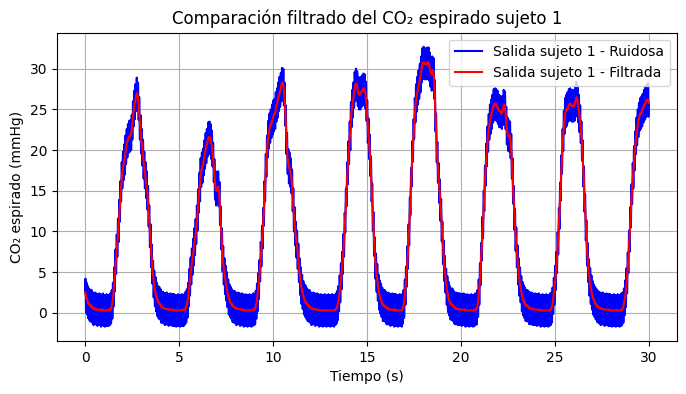

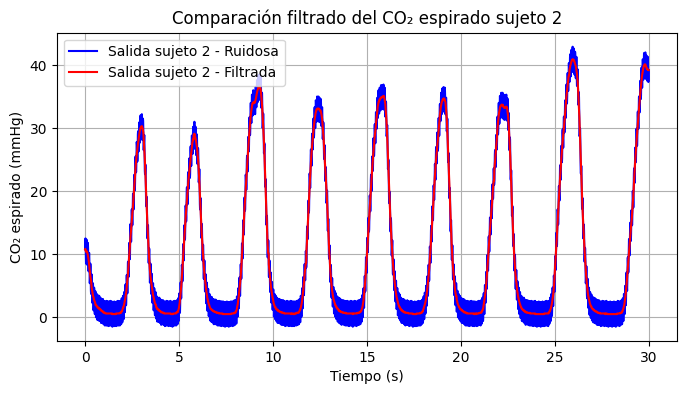

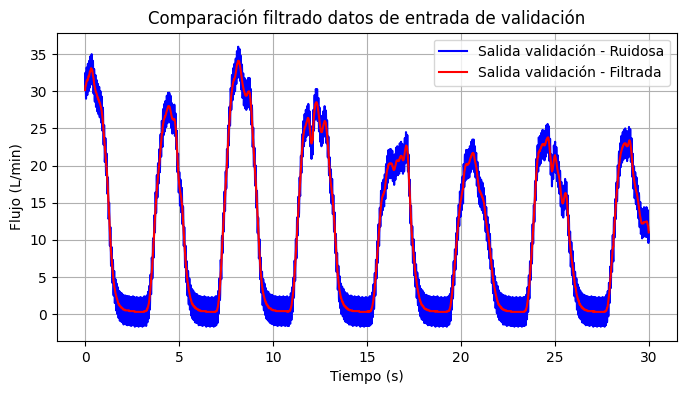

In [12]:
# Filtro para CO₂ espirado
g,h = butter(3,[14,16], btype='stop', fs=fs)
i,j = butter(3,[14,16], btype='stop', fs=fs)
k,l = butter(3,[14,16], btype='stop', fs=fs)
y2_filt = filtfilt(g, h, y2)
y1_filt = filtfilt(i, j, y1)
yv_filt = filtfilt(k, l, yv)

plt.figure(figsize=(8,4))
plt.plot(t, y1, 'b', label='Salida sujeto 1 - Ruidosa')
plt.plot(t, y1_filt, 'r', label='Salida sujeto 1 - Filtrada')
plt.title("Comparación filtrado del CO₂ espirado sujeto 1")
plt.xlabel("Tiempo (s)")
plt.ylabel("CO₂ espirado (mmHg)")
plt.legend()
plt.grid()

plt.figure(figsize=(8,4))
plt.plot(t, y2, 'b', label='Salida sujeto 2 - Ruidosa')
plt.plot(t, y2_filt, 'r', label='Salida sujeto 2 - Filtrada')
plt.title("Comparación filtrado del CO₂ espirado sujeto 2")
plt.xlabel("Tiempo (s)")
plt.ylabel("CO₂ espirado (mmHg)")
plt.legend()
plt.grid()

plt.figure(figsize=(8,4))
plt.plot(t, yv, 'b', label='Salida validación - Ruidosa')
plt.plot(t, yv_filt, 'r', label='Salida validación - Filtrada')
plt.title("Comparación filtrado datos de entrada de validación")
plt.xlabel("Tiempo (s)")
plt.ylabel("Flujo (L/min)")
plt.legend()
plt.grid()

#### **3.3.** Aplicamos Detrend para las entradas (Flujo)

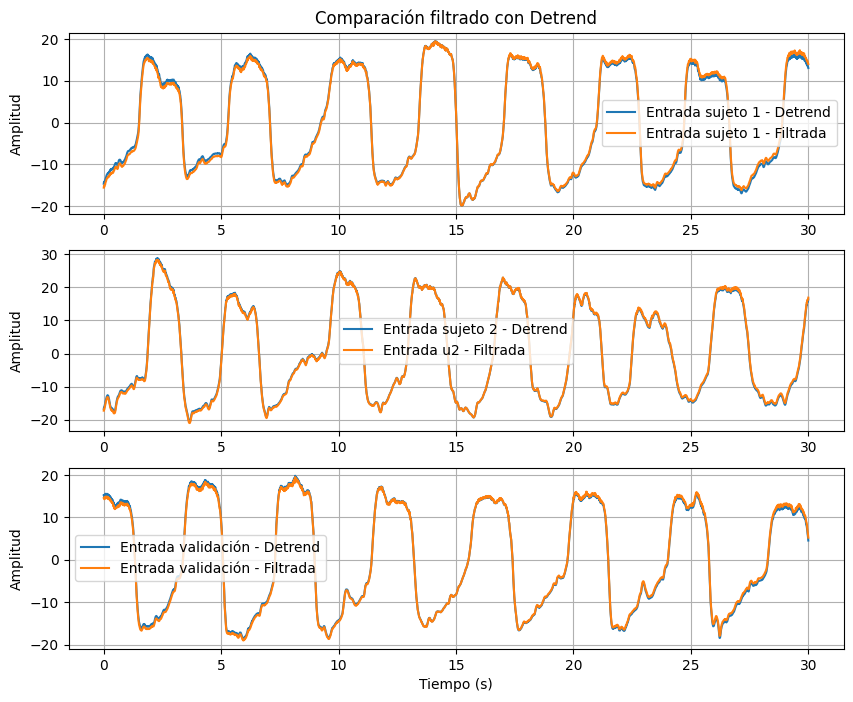

In [13]:
u1_detrend = detrend(u1_filt)
u2_detrend = detrend(u2_filt)
uv_detrend = detrend(uv_filt)

plt.figure(figsize=(10,8))

plt.subplot(311)
plt.plot(t,u1_detrend, label='Entrada sujeto 1 - Detrend')
plt.plot(t,u1_filt, label='Entrada sujeto 1 - Filtrada')
plt.title("Comparación filtrado con Detrend")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()

plt.subplot(312)
plt.plot(t,u2_detrend, label='Entrada sujeto 2 - Detrend')
plt.plot(t,u2_filt, label='Entrada u2 - Filtrada')
plt.ylabel("Amplitud")
plt.legend()
plt.grid()

plt.subplot(313)
plt.plot(t,uv_detrend, label='Entrada validación - Detrend')
plt.plot(t,uv_filt, label='Entrada validación - Filtrada')
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()

#### **3.4.** Aplicamos Detrend para las salidas (CO₂ espirado)

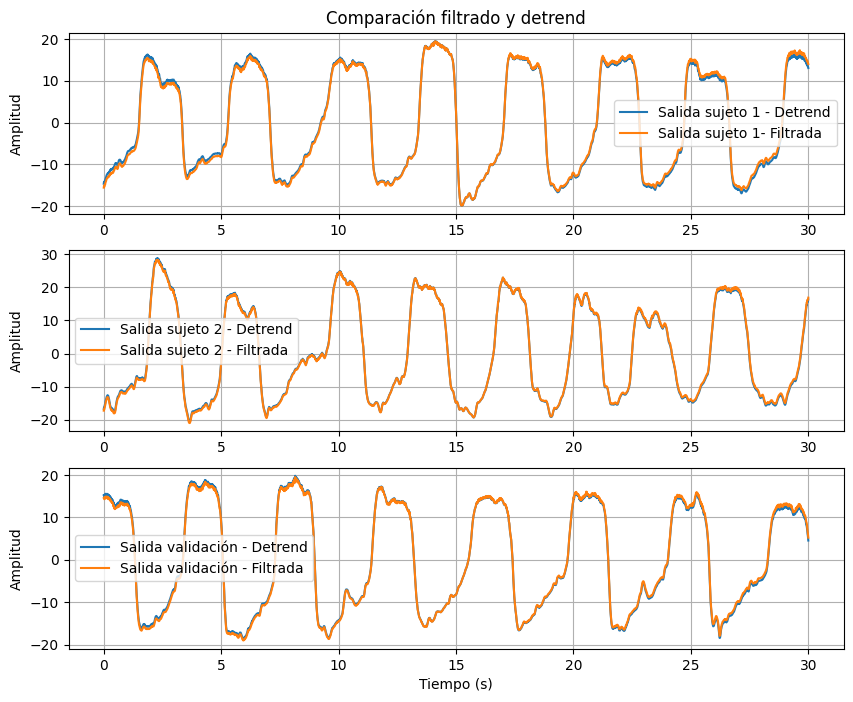

In [14]:
y1_detrend = detrend(y1_filt)
y2_detrend = detrend(y2_filt)
yv_detrend = detrend(yv_filt)

plt.figure(figsize=(10,8))

plt.subplot(311)
plt.plot(t,u1_detrend, label='Salida sujeto 1 - Detrend')
plt.plot(t,u1_filt, label='Salida sujeto 1- Filtrada')
plt.title("Comparación filtrado y detrend")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()

plt.subplot(312)
plt.plot(t,u2_detrend, label='Salida sujeto 2 - Detrend')
plt.plot(t,u2_filt, label='Salida sujeto 2 - Filtrada')
plt.ylabel("Amplitud")
plt.legend()
plt.grid()

plt.subplot(313)
plt.plot(t,uv_detrend, label='Salida validación - Detrend')
plt.plot(t,uv_filt, label='Salida validación - Filtrada')
plt.xlabel("Tiempo (s)")
plt.ylabel("Amplitud")
plt.legend()
plt.grid()

### **4.** Modelos: Sujeto 1
### **Modelo ARMAX**
$
A(q)[CO₂]_{exp}(n) = B(q)Q(n)A(q) + C(q)e(n)
$

C:\Users\fabio\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\signal\_ltisys.py:599: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  self.num, self.den = normalize(*system)


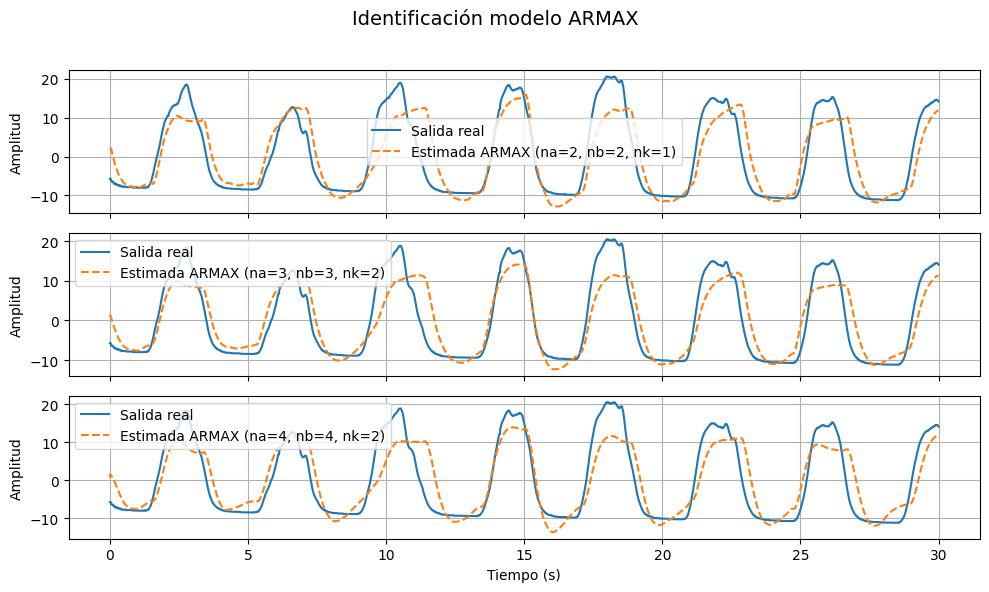

na,nb,nk,A,B
2,2,1,"[1.0, -1.753808623765046, 0.7594461568291182]","[0.0, -0.13341954874189094, 0.22212211859053047, -0.08375134407740192]"
3,3,2,"[1.0, -1.3025114343881439, -0.21675250115166908, 0.5229983990184762]","[0.0, 0.0, -0.10169377203488979, 0.15515852442833294, -0.005330703259968902, -0.04505650495579701]"
4,4,2,"[1.0, -1.2161411270773266, -0.10003052242695559, -0.028135866946992452, 0.3475897840195636]","[0.0, 0.0, -0.046909321559238194, -0.00042002252204815464, 0.09460960278562451, -0.011196256445015738, -0.03378689157208038]"


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [15]:
def polinomio(coefs, nombre='P'):
    terms = []
    for i, coef in enumerate(coefs):
        if abs(coef) < 1e-10:
            continue
        sign = '+' if coef >= 0 and i != 0 else ''
        terms.append(f"{sign}{coef:.4f}z^{{-{i}}}")
    return f"{nombre}(z) = " + ' '.join(terms)


# Parámetros: na, nb, nk
param_combinations_armax = [
    (2, 2, 1),
    (3, 3, 2),
    (4, 4, 2)]

# Grafica
fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
fig.suptitle('Identificación modelo ARMAX', fontsize=14)
colors = ['r', 'g', 'b']

resultados_armax = []
# Combinaciones para los diferentes ordenes
for i, (na, nb, nk) in enumerate(param_combinations_armax):
    # Modelo ARMAX
    model = armax(na, nb, [[0]], nk, u1_detrend, y1_detrend)
    # Coeficientes A y B
    A = model.A[0, 0]
    B = model.B[0, 0]
    # Creación del sistema
    system_1 = dlti(B, A, dt=ts)
    # Salida predicha
    t_out, y_signal = dlsim(system_1, u1_detrend)
    y_signal = y_signal.flatten()
    # señal
    y_sim_armax = y_signal
    # Guardar resultados en la lista
    resultados_armax.append({
        'na': na,
        'nb': nb,
        'nk': nk,
        'A': A.tolist(),
        'B': B.tolist(),
    })

    # Graficar la salida estimada
    axs[i].plot(t, y1_detrend, label='Salida real')
    axs[i].plot(t_out, y_sim_armax, linestyle='--', label=f'Estimada ARMAX (na={na}, nb={nb}, nk={nk})')
    axs[i].set_ylabel('Amplitud')
    axs[i].legend()
    axs[i].grid(True)

axs[-1].set_xlabel('Tiempo (s)')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# DataFrame resultados
df_resultados_armax = pd.DataFrame(resultados_armax)
pd.set_option('display.max_colwidth', None)
display(df_resultados_armax.style.hide(axis='index'))
df_resultados_armax['A_str'] = df_resultados_armax['A'].apply(lambda a: polinomio(a, nombre='A'))
df_resultados_armax['B_str'] = df_resultados_armax['B'].apply(lambda b: polinomio(b, nombre='B'))
for i in range(len(df_resultados_armax)):
    orden_str = f"\\text{{Orden }}({df_resultados_armax.loc[i, 'na']}, {df_resultados_armax.loc[i, 'nb']}, {df_resultados_armax.loc[i, 'nk']})"
    display(Math(orden_str))
    display(Math(df_resultados_armax.loc[i, 'A_str']))
    display(Math(df_resultados_armax.loc[i, 'B_str']))

### Validación modelo ARMAX

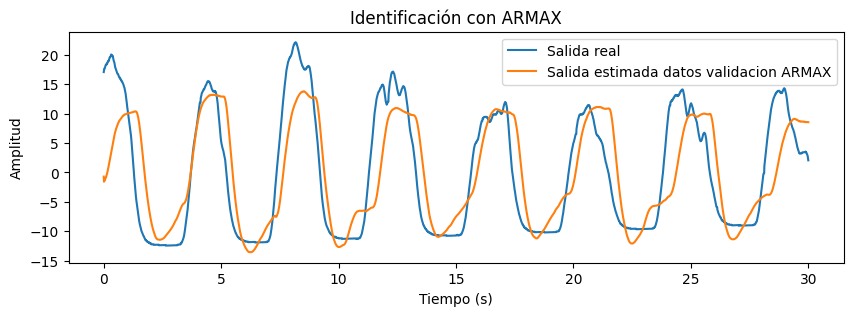

In [16]:
# Datos de validación
t_out, y_signal_val = dlsim(system_1, uv_detrend)
y_signal_val = y_signal_val.flatten()

y_sim_armax_val = y_signal_val

plt.figure(figsize=(10, 3))
plt.plot(t, yv_detrend, label='Salida real')
plt.plot(t, y_sim_armax_val, label='Salida estimada datos validacion ARMAX')
plt.title('Identificación con ARMAX')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()

### **Modelo OE:** Output Error

$
[CO₂]_{exp}(n) = \frac{B(q)}{F(q)}Q(n) + e(n)
$



C:\Users\fabio\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pysid\identification\solvers.py:42: FutureWarning: Beginning in SciPy 1.17, multidimensional input will be treated as a batch, not `ravel`ed. To preserve the existing behavior and silence this warning, `ravel` arguments before passing them to `toeplitz`.
  phi = concatenate((toeplitz(-y[L-1:Ny-1], -y[L-na:L][::-1]), toeplitz(u[L-nk:Nu-nk], u[L-nk-nb:L-nk+1][::-1])), axis=1)
C:\Users\fabio\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\signal\_ltisys.py:599: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  self.num, self.den = normalize(*system)


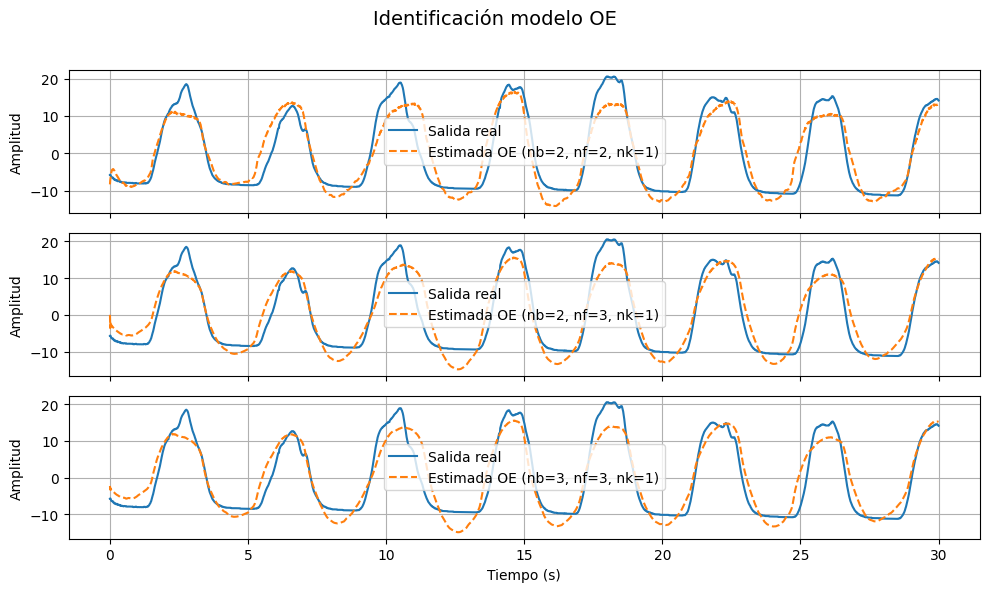

nb,nf,nk,B,F
2,2,1,"[0.0, 0.5639473183805668, -1.0899500906899127, 0.530008423039343]","[1.0, -1.8258971934469495, 0.8300860592721903]"
2,3,1,"[0.0, 0.24577164121431275, -0.4751956586733049, 0.2293949546894044]","[1.0, -1.4884660027325602, -0.008694301202077474, 0.49730209063483366]"
3,3,1,"[0.0, 0.1535262456126827, -0.1507768874491344, -0.14297321405747002, 0.14019707014287822]","[1.0, -1.453464877016655, -0.07930486703387671, 0.5329115200444317]"


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [17]:
# Parámetros: nb, nf, nk
param_combinations_oe = [
    (2, 2, 1),
    (2, 3, 1),
    (3, 3, 1)]

# Grafica
fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
fig.suptitle('Identificación modelo OE', fontsize=14)
colors = ['r', 'g', 'b']


resultados_oe = []
# Combinaciones para los diferentes ordenes
for i, (nb, nf, nk) in enumerate(param_combinations_oe):
    # Modelo OE
    model = oe(nb, nf, nk, u1_detrend, y1_detrend)
    # Coeficientes B y F
    B = model.B[0, 0]
    F = model.F[0, 0]
    # Creación del sistema
    system = dlti(B, F, dt=ts)
    # Salida predicha
    t_out, y_tf = dlsim(system, u1_detrend)
    y_tf = y_tf.flatten()
    y_sim_oe = y_tf
    # Guardar resultados en la lista
    resultados_oe.append({
        'nb': nb,
        'nf': nf,
        'nk': nk,
        'B': B.tolist(),
        'F': F.tolist(),
    })

    # Graficar la salida estimada
    axs[i].plot(t, y1_detrend, label='Salida real')
    axs[i].plot(t_out, y_sim_oe, linestyle='--', label=f'Estimada OE (nb={nb}, nf={nf}, nk={nk})')
    axs[i].set_ylabel('Amplitud')
    axs[i].legend()
    axs[i].grid(True)

axs[-1].set_xlabel('Tiempo (s)')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# DataFrame resultados
df_oe = pd.DataFrame(resultados_oe)
pd.set_option('display.max_colwidth', None)
display(df_oe.style.hide(axis='index'))
df_oe['B_str'] = df_oe['B'].apply(lambda b: polinomio(b, nombre='B'))
df_oe['F_str'] = df_oe['F'].apply(lambda f: polinomio(f, nombre='F'))
for i in range(len(df_oe)):
    orden_str = f"\\text{{Orden }}({df_oe.loc[i, 'nb']}, {df_oe.loc[i, 'nf']}, {df_oe.loc[i, 'nk']})"
    display(Math(orden_str))
    display(Math(df_oe.loc[i, 'B_str']))
    display(Math(df_oe.loc[i, 'F_str']))


### Validación modelo OE

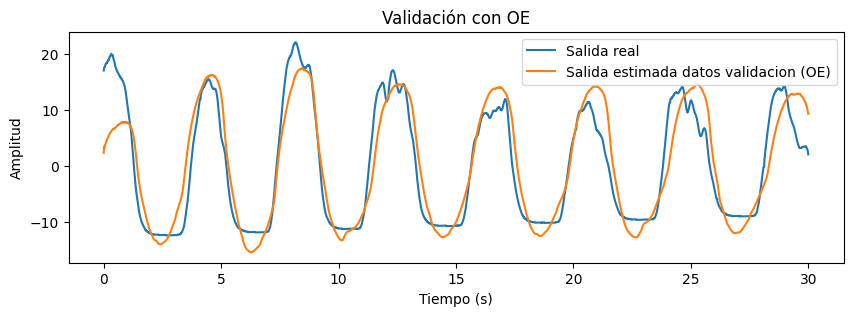

In [18]:
# Datos de validación
t_out_val, y_sim_oe_val = dlsim(system, uv_detrend)
y_sim_oe_val = y_sim_oe_val.flatten()
y_sim_oe_val = y_sim_oe_val

plt.figure(figsize=(10, 3))
plt.plot(t, yv_detrend, label='Salida real')
plt.plot(t, y_sim_oe_val, label='Salida estimada datos validacion (OE)')
plt.title('Validación con OE')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()

### Modelo BJ (Box-Jenkins) 
$
[CO₂]_{exp}(n) = \frac{B(q)}{F(q)}Q(n) + \frac{C(q)}{D(q)}e(n)
$

C:\Users\fabio\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\pysid\identification\solvers.py:42: FutureWarning: Beginning in SciPy 1.17, multidimensional input will be treated as a batch, not `ravel`ed. To preserve the existing behavior and silence this warning, `ravel` arguments before passing them to `toeplitz`.
  phi = concatenate((toeplitz(-y[L-1:Ny-1], -y[L-na:L][::-1]), toeplitz(u[L-nk:Nu-nk], u[L-nk-nb:L-nk+1][::-1])), axis=1)
C:\Users\fabio\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\signal\_ltisys.py:599: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  self.num, self.den = normalize(*system)


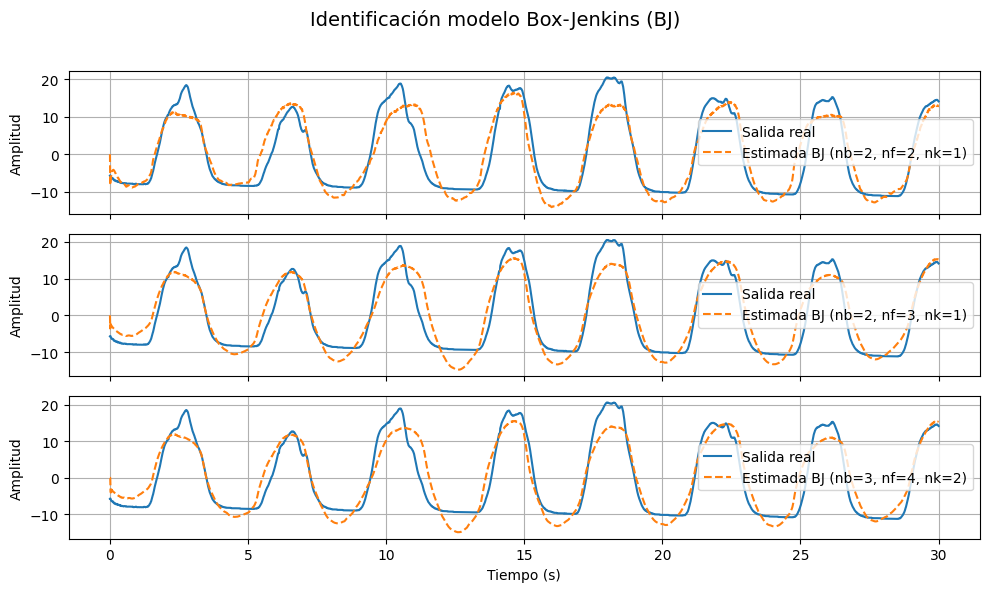

nb,nf,nk,B,F
2,2,1,"[0.0, 0.5639473183805668, -1.0899500906899127, 0.530008423039343]","[1.0, -1.8258971934469495, 0.8300860592721903, 0.0]"
2,3,1,"[0.0, 0.24577164121431275, -0.4751956586733049, 0.2293949546894044]","[1.0, -1.4884660027325602, -0.008694301202077474, 0.49730209063483366]"
3,4,2,"[0.0, 0.0, 0.20315014032087264, -0.19394795466628734, -0.20103662636566993, 0.1917989141340951]","[1.0, -1.3317792735394522, 0.004505893396574614, 0.00406080243693826, 0.32339508156303787, 0.0]"


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

In [17]:
# Combinaciones de órdenes para BJ: (nb, nf, nk)
param_combinations_bj = [
    (2, 2, 1),
    (2, 3, 1),
    (3, 4, 2)
]

# Gráfica
fig, axs = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
fig.suptitle('Identificación modelo Box-Jenkins (BJ)', fontsize=14)
colors = ['r', 'g', 'b']

resultados_bj = []
for i, (nb, nf, nk) in enumerate(param_combinations_bj):
    # Crear modelo BJ
    model = bj(nb, [[0]], [[0]], nf, nk, u1_detrend, y1_detrend)

    # Extraer polinomios
    B = model.B[0, 0]
    F = model.F[0, 0]

    # Asegurar que B y F tengan la misma longitud
    max_len = max(len(B), len(F))
    B = np.pad(B, (0, max_len - len(B)), 'constant')
    F = np.pad(F, (0, max_len - len(F)), 'constant')

    # Crear sistema de transferencia para la parte determinística B/F
    system_bj_1 = dlti(B, F, dt=ts)
    t_out, y_bj_signal = dlsim(system_bj_1, u1_detrend)
    y_bj_signal = y_bj_signal.flatten()
    # señal
    y_sim_bj = y_bj_signal

    resultados_bj.append({
        'nb': nb, 'nf': nf, 'nk': nk,
        'B': B.tolist(), 'F': F.tolist()

    })

    # Graficar
    axs[i].plot(t , y1_detrend, label='Salida real')
    axs[i].plot(t_out, y_sim_bj, '--', label=f'Estimada BJ (nb={nb}, nf={nf}, nk={nk})')
    axs[i].set_ylabel('Amplitud')
    axs[i].legend()
    axs[i].grid(True)

axs[-1].set_xlabel('Tiempo (s)')
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Mostrar resultados
df_bj = pd.DataFrame(resultados_bj)
pd.set_option('display.max_colwidth', None)
display(df_bj.style.hide(axis='index'))

# Mostrar polinomios en forma simbólica
df_bj['B_str'] = df_bj['B'].apply(lambda b: polinomio(b, nombre='B'))
df_bj['F_str'] = df_bj['F'].apply(lambda f: polinomio(f, nombre='F'))

for i in range(len(df_bj)):
    orden_str = f"\\text{{Orden }}(nb={df_bj.loc[i, 'nb']}, nf={df_bj.loc[i, 'nf']}, nk={df_bj.loc[i, 'nk']})"
    display(Math(orden_str))
    display(Math(df_bj.loc[i, 'B_str']))
    display(Math(df_bj.loc[i, 'F_str']))



### Validación modelo BOX-JENKINS (BJ)

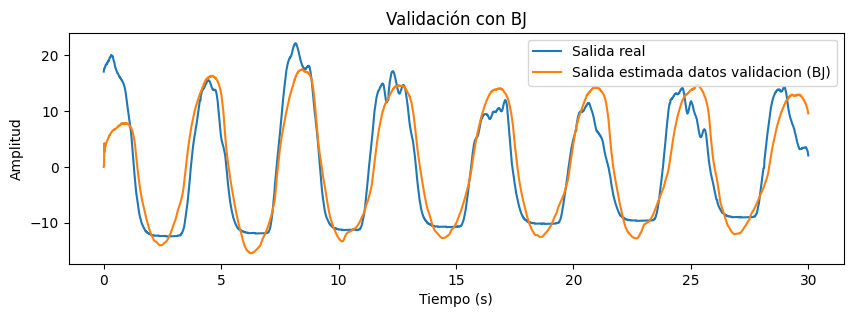

In [18]:
# Revisando con datos de validación
t_out, y_signal_val_bj = dlsim(system_bj_1, uv_detrend)
y_signal_val_bj = y_signal_val_bj.flatten()

y_sim_bj_val = y_signal_val_bj

plt.figure(figsize=(10, 3))
plt.plot(t, yv_detrend, label='Salida real')
plt.plot(t, y_sim_bj_val, label='Salida estimada datos validacion (BJ)')
plt.title('Validación con BJ')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.legend()

### **5.1** Elección mejor modelo: RMSE, FIT y akaike

In [19]:
def calcular_metricas(y_real, y_pred):
    # Error cuadrático medio
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    # Porcentaje de ajuste (FIT)
    fit = 100 * (1 - np.linalg.norm(y_real - y_pred) / np.linalg.norm(y_real - np.mean(y_real)))

    return {
        'RMSE': rmse,
        'FIT': fit
    }



def calcular_metricas_de_modelo(df, index, u, y_real, ts):
    fila = df.iloc[index]
    
    # Detectar qué coeficientes tiene el modelo
    A = np.array(fila['A']) if 'A' in fila and fila['A'] is not None else None
    B = np.array(fila['B']) if 'B' in fila and fila['B'] is not None else None
    C = np.array(fila['C']) if 'C' in fila and fila['C'] is not None else None
    D = np.array(fila['D']) if 'D' in fila and fila['D'] is not None else None
    F = np.array(fila['F']) if 'F' in fila and fila['F'] is not None else None

    # Seleccionar estructura según el modelo
    if A is not None and B is not None and C is None and D is None and F is None:
        # Modelo ARX
        den = A
        num = B

    elif A is None and B is not None and C is not None and D is not None and F is not None:
        # Modelo BJ
        den = F
        num = B

    elif A is not None and B is not None and C is not None and D is None and F is None:
        # Modelo ARMAX
        den = A
        num = B

    elif A is None and B is not None and C is None and D is None and F is not None:
        # Modelo OE
        den = F
        num = B

    else:
        raise ValueError("No se reconoce la estructura del modelo a partir de los coeficientes.")

    # Asegurar compatibilidad para dlsim
    max_len = max(len(num), len(den))
    num = np.pad(num, (0, max_len - len(num)), 'constant')
    den = np.pad(den, (0, max_len - len(den)), 'constant')

    # Simulación
    system = dlti(num, den, dt=ts)
    _, y_pred = dlsim(system, u)
    y_pred = y_pred.flatten()

    # Métricas
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    fit = 100 * (1 - np.linalg.norm(y_real - y_pred) / np.linalg.norm(y_real - np.mean(y_real)))

    return {'RMSE': rmse, 'FIT': fit, 'y_pred': y_pred}

In [20]:
# modelos Evaluacion
modelos = {
    'BJ': y_sim_bj,
    'ARMAX': y_sim_armax,
    'OE': y_sim_oe
}

# Calcular métricas
resultados = []
for nombre, y_est in modelos.items():
    metricas = calcular_metricas(y1_detrend, y_est)
    metricas['Modelo'] = nombre
    resultados.append(metricas)

# Convertir a DataFrame
df_resultados = pd.DataFrame(resultados)
df_resultados = df_resultados[['Modelo', 'RMSE', 'FIT']]

# Ranking combinado: menor RMSE (rank 1 es mejor), mayor FIT (rank 1 es mejor)
df_resultados['Rank_RMSE'] = df_resultados['RMSE'].rank(method='min')
df_resultados['Rank_FIT'] = df_resultados['FIT'].rank(method='min', ascending=False)
df_resultados['Score_Total'] = df_resultados['Rank_RMSE'] + df_resultados['Rank_FIT']

# Ordenar por el score total
df_resultados = df_resultados.sort_values(by='Score_Total')

display(df_resultados)

# Mejor modelo
mejor_modelo = df_resultados.iloc[0]
print(f"El mejor modelo según RMSE + FIT combinados es: {mejor_modelo['Modelo']}")


,Modelo,RMSE,FIT,Rank_RMSE,Rank_FIT,Score_Total
2,OE,3.631255,64.931827,1.0,1.0,2.0
0,BJ,3.632184,64.922859,2.0,2.0,4.0
1,ARMAX,4.975829,51.946855,3.0,3.0,6.0


El mejor modelo según RMSE + FIT combinados es: OE


In [21]:
def calcular_aic(y, y_model, k):
    N = len(y)
    error = y - y_model
    mse = np.mean(error**2)
    aic = N * np.log(mse) + 2 * k
    return aic


for i, (nb, nf, nk) in enumerate(param_combinations_oe):
    k = nb + nf
    aic = calcular_aic(y1_detrend, y_sim_oe, k)
    print(f"Modelo OE({nb},{nf},{nk}): AIC = {aic:.2f}")

Modelo OE(2,2,1): AIC = 7748.05
Modelo OE(2,3,1): AIC = 7750.05
Modelo OE(3,3,1): AIC = 7752.05


#### Modelo: **Sujeto 1**

${[CO₂]_{exp}\left(z\right)}=\ \frac{0.5639473183805668\ z^{-1}-\ 1.0899500906899127\ z^{-2}+\ 0.530008423039343\ z^{-3}}{1-\ 1.8258971934469495\ z^{-1}+\ 0.8300860592721903\ z^{-2}}{Q\left(z\right)}+{e\left(z\right)}$

## **6.** Sensibilidad
#### Respecto al Sujeto 1

In [22]:

B_list = resultados_oe[0]['B']
F_list = resultados_oe[0]['F']
print ("\nParametros B:",B_list)
print ("\nParametros F:",F_list)


Parametros B: [0.0, 0.5639473183805668, -1.0899500906899127, 0.530008423039343]

Parametros F: [1.0, -1.8258971934469495, 0.8300860592721903]



Coeficientes reales B: [ 0.56394732 -1.08995009  0.53000842]
Coeficientes reales F: [-1.82589719  0.83008606]


C:\Users\fabio\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\signal\_ltisys.py:599: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  self.num, self.den = normalize(*system)


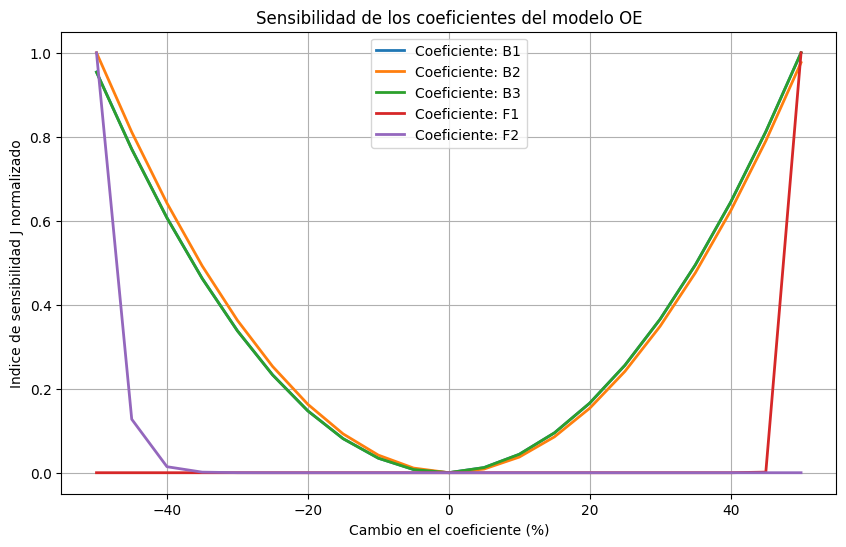

In [19]:
B_full = np.array(resultados_oe[0]['B'])
F_full = np.array(resultados_oe[0]['F'])

idx_B_start = np.argmax(B_full != 0)      
B_real = B_full[idx_B_start:]             

F_trimmed = F_full[1:]
idx_F_end = np.max(np.where(F_trimmed != 0)) + 1
F_real = F_trimmed[:idx_F_end]
print("\nCoeficientes reales B:", B_real)
print("Coeficientes reales F:", F_real)

# parametros
pararef = np.concatenate([B_real, F_real])
Np = len(pararef)

# Función que simula B y F
def fn_sys(params, t, u):
    # reconstruir B
    B = B_full.copy()
    B[idx_B_start : idx_B_start + len(B_real)] = params[:len(B_real)]
    
    # reconstruir F
    F = F_full.copy()
    F[1 : 1 + len(F_real)] = params[len(B_real):]

    # TransferFunction
    system = TransferFunction(B, F)
    _, y_tf, _ = lsim(system, U=u, T=t)
    return y_tf.flatten()

# Analisis sensibilidad
step = 5
para_change = np.arange(-50, 51, step)
num_steps = len(para_change)

J = np.zeros((num_steps, Np))

for i in range(Np):
    for k in range(num_steps):
        para = pararef.copy()
        para[i] = pararef[i] * (1 + para_change[k] / 100)   # variar el parámetro

        y_pred = fn_sys(para, t, u1_detrend)
        e = y_pred - y1_detrend
        J[k, i] = np.sum(e**2)

# Grafico
labels = [f"B{i+1}" for i in range(len(B_real))] + \
         [f"F{i+1}" for i in range(len(F_real))]

# Normalización
J_normalized = J / np.max(J, axis=0)

plt.figure(figsize=(10, 6))
for i in range(Np):
    plt.plot(para_change, J_normalized[:, i], label=f'Coeficiente: {labels[i]}', linewidth=2)

plt.xlabel('Cambio en el coeficiente (%)')
plt.ylabel('Indice de sensibilidad J normalizado')
plt.title('Sensibilidad de los coeficientes del modelo OE')
plt.legend()
plt.grid(True)
plt.show()


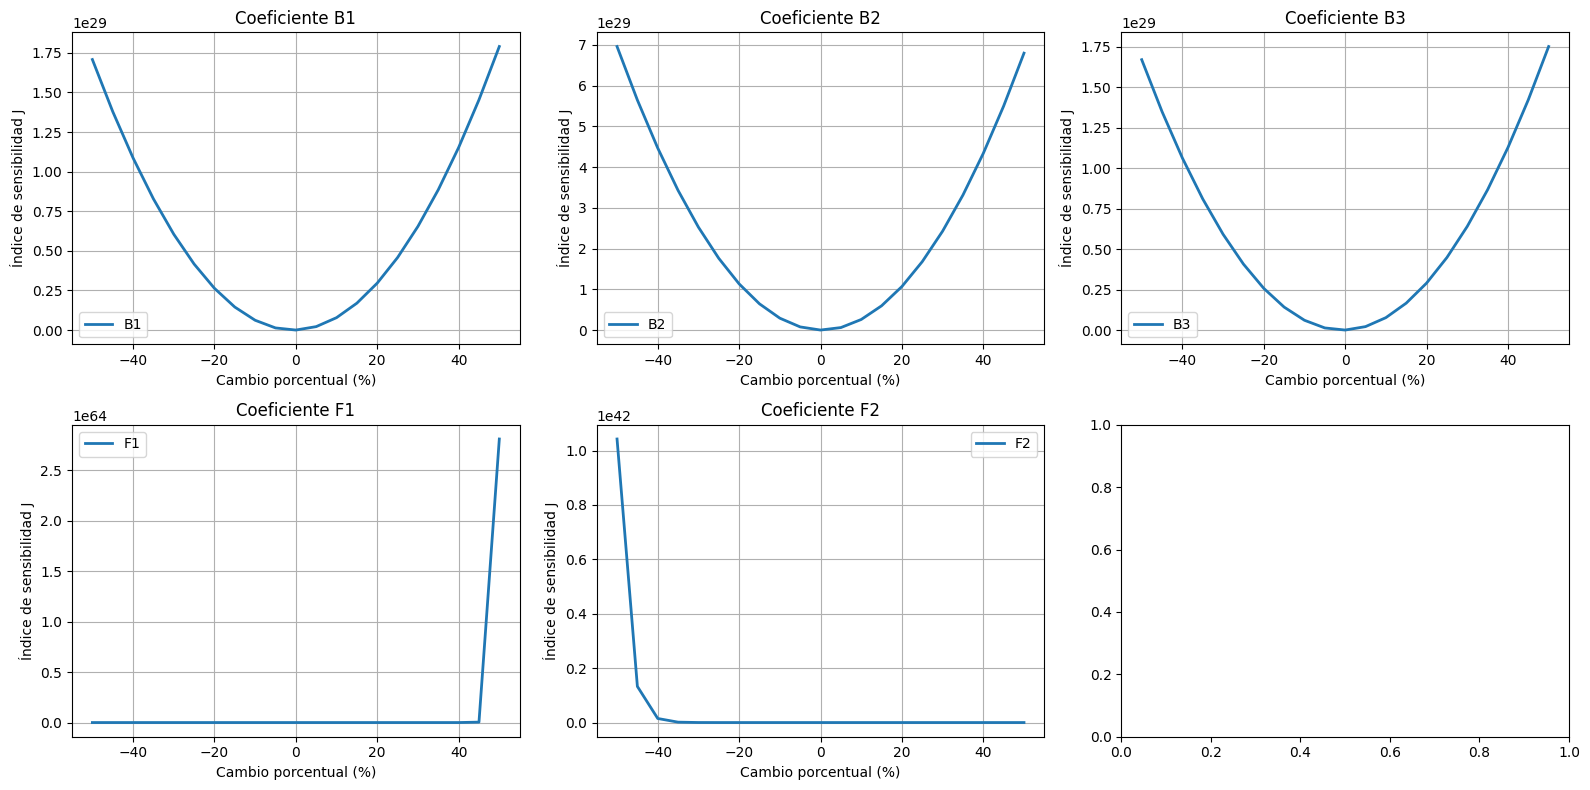

In [ ]:
# Etiquetas para cada coeficiente
labels = ['B1', 'B2', 'B3', 'F1', 'F2']

# Creamos figura para cada parametrep
fig, axs = plt.subplots(2, 3, figsize=(16, 8))
axs = axs.flatten()

# Recorremos cada coeficiente
for i in range(Np):  # Np=8
    axs[i].plot(para_change, J[:, i], label=f'{labels[i]}', linewidth=2)
    axs[i].set_title(f'Coeficiente {labels[i]}', fontsize=12)
    axs[i].set_xlabel('Cambio porcentual (%)')
    axs[i].set_ylabel('Índice de sensibilidad J')
    axs[i].grid(True)
    axs[i].legend()

plt.tight_layout()
plt.show()



## **7.** Optimización
#### Respecto al sujeto 2

In [ ]:
def fn_coste(theta):
    global t, u2_detrend, y2_detrend 
    b0 = 0
    f0 = 1
    f1 = -1.82589719
    B = [b0, theta[0], theta[1], theta[2]]
    F = [f0, f1, theta[3]] 
    # Construcción del sistema
    system = TransferFunction(B, F)
    # Simulación
    _, y_pred, _ = lsim(system, U= u2_detrend, T=t)
    # Cálculo del error cuadrático
    e = y2_detrend - y_pred
    J = np.sum(e ** 2)

    return J

In [60]:
b1, b2, b3 = B_full[1:]  
f2 = F_full[2]

# Semilla
theta_init = np.array([(1/B_full[1]), (1/B_full[2]), (1/B_full[3]), (1/F_full[2])])
res = minimize(fn_coste, theta_init, method='Powell')

# Resultados
print('\nValores de theta obtenidos:')
print(res.x)

print('\nResultado completo del optimizador:')
print(res)


C:\Users\fabio\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\signal\_ltisys.py:599: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  self.num, self.den = normalize(*system)



Valores de theta obtenidos:
[ 1.55160574 -2.83307256  1.86076054  1.1992483 ]

Resultado completo del optimizador:
 message: Optimization terminated successfully.
 success: True
  status: 0
     fun: 2152364.97347205
       x: [ 1.552e+00 -2.833e+00  1.861e+00  1.199e+00]
     nit: 8
   direc: [[ 1.000e+00  0.000e+00  0.000e+00  0.000e+00]
           [ 0.000e+00  1.000e+00  0.000e+00  0.000e+00]
           [ 0.000e+00  0.000e+00  1.000e+00  0.000e+00]
           [ 0.000e+00  0.000e+00  0.000e+00  1.000e+00]]
    nfev: 308


Numerador: [0, 1.5516057388796374, -2.8330725586098846, 1.8607605382448416]
Denominador: [1, -1.82589719, 1.199248295886727]


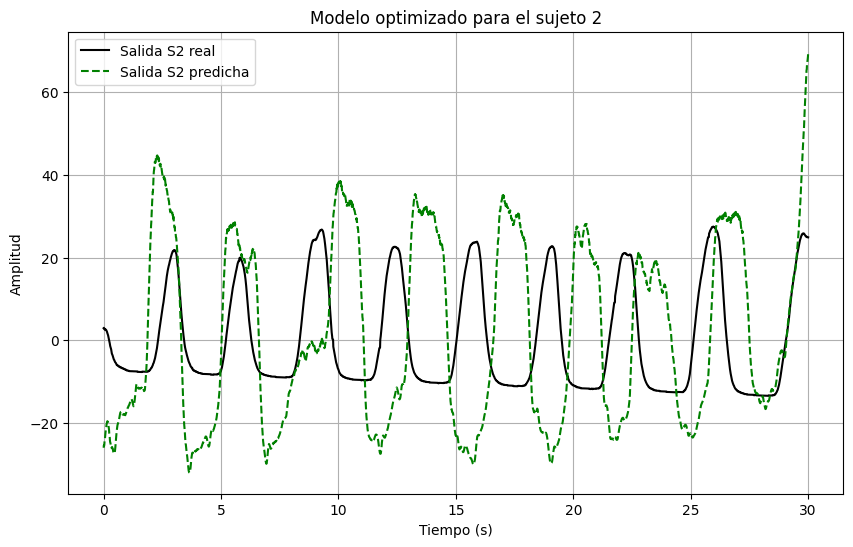

In [62]:
num = [0, res.x[0], res.x[1], res.x[2]]
den = [1, -1.82589719, res.x[3]]
print('Numerador:', num)
print('Denominador:', den)
system = TransferFunction(num, den)
_, ypred_s2, _ = lsim(system, U=u2_detrend, T=t)

# Graficar
plt.figure(figsize=(10,6))
plt.plot(t, y2_detrend, 'k', label='Salida S2 real')
plt.plot(t, ypred_s2, color='green', label='Salida S2 predicha', linestyle='--')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.title('Modelo optimizado para el sujeto 2')
plt.legend()
plt.grid(True)
plt.show()



Probando semilla inicial k=0.8: [ 0.5155949  -0.28237893  0.42993173  0.83385568]


C:\Users\fabio\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\scipy\signal\_ltisys.py:599: BadCoefficients: Badly conditioned filter coefficients (numerator): the results may be meaningless
  self.num, self.den = normalize(*system)


Valores optimizados: [-0.09284866 -0.31286288  0.42412685  0.81820533]
Valor final de J: 8.143298507839203e+21

Probando semilla inicial k=0.9: [ 0.58004426 -0.3176763   0.4836732   0.83385568]
Valores optimizados: [-0.10445473 -0.35197052  0.4771427   0.81820533]
Valor final de J: 1.0309501649741979e+22

Probando semilla inicial k=1.0: [ 0.64449362 -0.35297366  0.53741466  0.83385568]
Valores optimizados: [-0.11606081 -0.3910786   0.53015856  0.81820533]
Valor final de J: 1.2723899316485403e+22

Probando semilla inicial k=1.1: [ 0.70894298 -0.38827103  0.59115613  0.83385568]
Valores optimizados: [-0.1276669  -0.43018646  0.58317442  0.81820533]
Valor final de J: 1.5395920580372544e+22

Probando semilla inicial k=1.2: [ 0.77339234 -0.4235684   0.6448976   0.83385568]
Valores optimizados: [-0.13927297 -0.46929433  0.63619027  0.81820533]
Valor final de J: 1.8322413481621558e+22

Resumen de todos los resultados:
k=0.8 -> J final=8143298507839203442688.0000 | theta=[-0.09284866 -0.312862

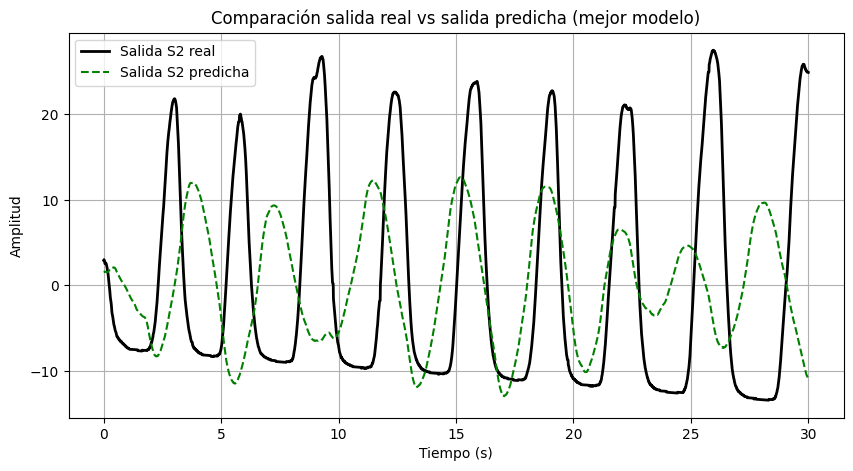

In [68]:
b1, b2, b3, f2 = 1.5516057388796374, -2.8330725586098846, 1.8607605382448416, 1.199248295886727
k_values = np.arange(0.8, 1.21, 0.1)

resultados = []

for k in k_values:
    theta_init = np.array([k/b1, k/b2, k/b3, 1/f2])
    print(f"\nProbando semilla inicial k={k:.1f}: {theta_init}")

    # Optimizamos
    res2 = minimize(fn_coste, theta_init, method='Powell')
    
    print(f"Valores optimizados: {res2.x}")
    print(f"Valor final de J: {res2.fun}")
    
    resultados.append({'k': k, 'theta': res2.x, 'J': res2.fun})

# Comparar resultados
print("\nResumen de todos los resultados:")
for r in resultados:
    print(f"k={r['k']:.1f} -> J final={r['J']:.4f} | theta={r['theta']}")

# Escoger el mejor según menor J
mejor = min(resultados, key=lambda x: x['J'])
print(f"\nMejor k={mejor['k']:.1f} con J={mejor['J']:.4f} y theta={mejor['theta']}")

# Simular con el mejor modelo encontrado
num = [0, mejor['theta'][0], mejor['theta'][1], mejor['theta'][2]]
den = [1, mejor['theta'][3], 2.30256891]

system = TransferFunction(num, den)
_, ypred_best, _ = lsim(system, U=u2_detrend, T=t)

plt.figure(figsize=(10, 5))
plt.plot(t, y2_detrend, 'k', label='Salida S2 real', linewidth=2)
plt.plot(t, ypred_best, 'g--', label='Salida S2 predicha')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.title('Comparación salida real vs salida predicha (mejor modelo)')
plt.legend()
plt.grid()
plt.show()


#### Modelo optimo: **Sujeto 2**
${[CO₂]_{exp}\left(z\right)}=\ \frac{0.01149065\ z^{-1}-\ 0.3850875\ z^{-2}+\ 0.38102048\ z^{-3}}{1-\ 1.8258971934469495\ z^{-1}+\ 0.82199067\ z^{-2}}{Q\left(z\right)}+{e\left(z\right)}$

## **8.** Analisis de tiempo y frecuencia
### **8.1** Tiempo:

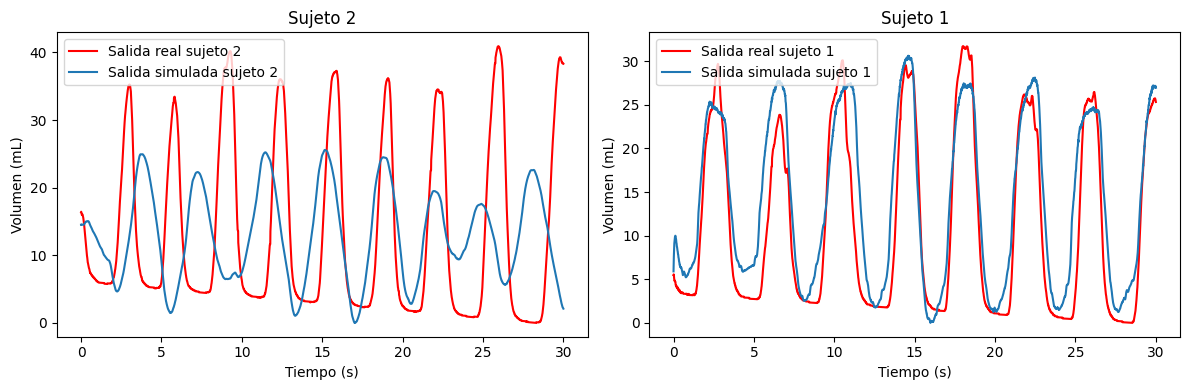

In [70]:
num1 = [0.5639473183805668, -1.0899500906899127, 0.530008423039343]
den1 = [1, -1.8258971934469495, 0.8300860592721903]
num2 = [0.01149065, -0.3850875, 0.38102048]
den2 = [1, -1.8258971934469495, 0.82199067]
system = dlti(num2, den2, dt=t[1] - t[0])
system2 = dlti(num1, den1, dt=t[1] - t[0])
_, y_pred = dlsim(system, u2_detrend)
_, y_pred2 = dlsim(system2, u1_detrend)
y_pred_s2 = y_pred.flatten()
y_pred_s3 = y_pred2.flatten()

# Acomodando la señal de salida positiva
y1_base = y1_detrend + abs(np.min(y1_detrend))
y2_base = y2_detrend + abs(np.min(y2_detrend))
y1_bpre = ypred_best + abs(np.min(ypred_best))
y2_bpre = y_pred_s3 + abs(np.min(y_pred_s3))

plt.figure(figsize = (12, 4))

plt.subplot(121)
plt.plot(t, y2_base, color = 'r', label="Salida real sujeto 2")
plt.plot(t, y1_bpre, label="Salida simulada sujeto 2")
plt.title("Sujeto 2")
plt.ylabel('Volumen (mL)')
plt.xlabel('Tiempo (s)')
plt.tight_layout()
plt.legend()

plt.subplot(122)
plt.plot(t, y1_base, color = 'r', label="Salida real sujeto 1")
plt.plot(t, y2_bpre, label="Salida simulada sujeto 1")
plt.title("Sujeto 1")
plt.ylabel('Volumen (mL)')
plt.xlabel('Tiempo (s)')
plt.tight_layout()
plt.legend()

### **8.2** Frecuencia:

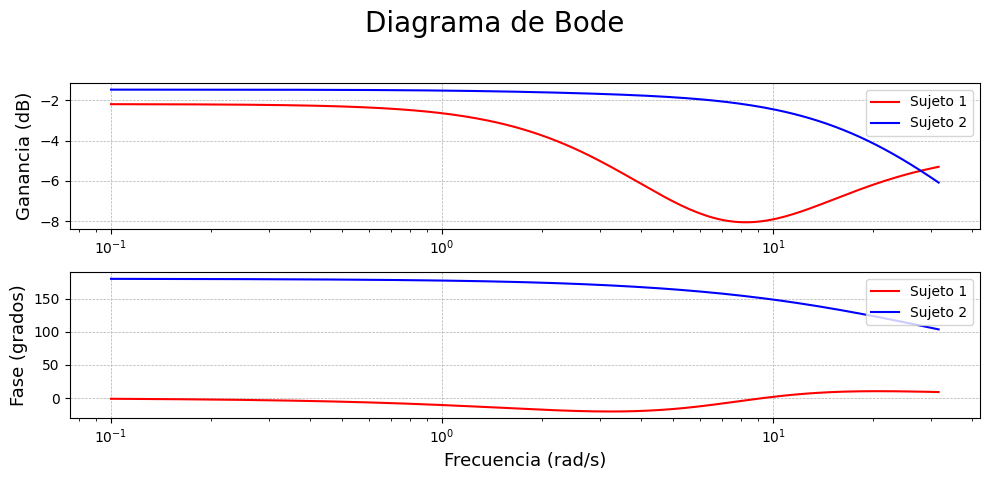

In [66]:
# Frecuencia
w = np.logspace(-1, 1.5, 200)

def convertir_a_continuo(num_d, den_d, ts):
    A, B, C, D = tf2ss(num_d, den_d)
    I = np.eye(A.shape[0])
    M = np.linalg.inv(I + A)
    A_c = (2/ts) * (A - I) @ M
    B_c = (2/ts) * M @ B
    C_c = C @ M
    D_c = D - C @ M @ B
    num_c, den_c = ss2tf(A_c, B_c, C_c, D_c)
    return TransferFunction(num_c, den_c)

sys1 = convertir_a_continuo(num1, den1, ts)
sys2 = convertir_a_continuo(num2, den2, ts)
w_out1, mag1, phase1 = bode(sys1, w)
w_out2, mag2, phase2 = bode(sys2, w)

plt.figure(figsize=(10, 5))
plt.suptitle('Diagrama de Bode', fontsize=20)

# Ganancia
plt.subplot(2, 1, 1)
plt.semilogx(w_out1, mag1, 'r', label='Sujeto 1')
plt.semilogx(w_out2, mag2, 'b', label='Sujeto 2')
plt.ylabel('Ganancia (dB)', fontsize=13)
plt.grid(True, linestyle='--', linewidth=0.5)
plt.legend()

# Fase
plt.subplot(2, 1, 2)
plt.semilogx(w_out1, phase1, 'r', label='Sujeto 1')
plt.semilogx(w_out2, phase2, 'b', label='Sujeto 2')
plt.xlabel('Frecuencia (rad/s)', fontsize=13)
plt.ylabel('Fase (grados)', fontsize=13)
plt.grid(True, linestyle='--', linewidth=0.5)
plt.legend(loc='upper right')

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.savefig('Bode')
plt.show()

